In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar

start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'

alcohol=0
n_rc=14
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800


# AMPA
g_AMPA_ext_E = 2.08 * nS #20.8
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25*nS #1.25 * nS 0.8
g_GABA_I = 0.973*nS #1.25 * nS 0.8
tau_GABA = 10. * ms


#STDP/iSTDP
Apre = 0.012
Apost = -0.0115 
w_max = 3 #1.5


# Apre_i = -0.005   
# Apost_i = 0.005
Apre_i = -0.011   
Apost_i = 0.015
w_max_i = 5.0

#gif 
save_interval = 0.2*second  
frames_rec=[]
frames_inp=[]

# rf_indices = [1,25,33,46,53,64,77,85,96]
center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.4   # 40% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.2   # 20% reduction of excitatory drive onto I
ALC_INC_GABA_E = 0.5   # 50% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.3   # 30% increase of inhibitory drive onto I
ALC_Ibias_E    = -40*pA  # extra hyperpolarizing bias on E during alcohol (optional)
ALC_Ibias_I    = -10*pA  # small bias on I (optional)

# frames_fr=[]
# def plot_firing_rate_heatmap(t,rates,n_output_rows, n_output_columns,frames_list):

#     firing_rate_grid = rates.reshape(n_output_rows, n_output_columns)
    
#     plt.figure(figsize=(6, 6))
#     #plt.imshow(firing_rate_grid, cmap='hot', interpolation='nearest')
#     im = plt.imshow(firing_rate_grid, cmap='hot', interpolation='nearest', vmin=0, vmax=50)
#     cbar = plt.colorbar(im)  # <- this adds the legend
#     cbar.set_label('Firing rate (Hz)')  # label for the colorbar
#     plt.title(f'Firing rates at t = {t/ms:.0f} ms')
#     frames_list.append(plt.gcf())
#     plt.close()

# def plot_firing_rate_heatmap(t, rates, writer, n_output_rows, n_output_columns, temp_file='temp_frame.png'):
#     rate_grid = rates.reshape(n_output_rows, n_output_columns)

#     fig, ax = plt.subplots(figsize=(5, 5))
#     im = ax.imshow(rate_grid, cmap='hot', interpolation='nearest', vmin=0, vmax=50)
#     cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
#     cbar.set_label('Firing rate (Hz)')
#     ax.set_title(f'Firing rates at t = {t/ms:.0f} ms')
#     ax.set_xlabel("X neurons")
#     ax.set_ylabel("Y neurons")

#     # Save frame as PNG and add to GIF
#     fig.savefig(temp_file, bbox_inches='tight')
#     writer.append_data(imageio.imread(temp_file))
#     plt.close(fig)


def plot_sum_weights_gif(t, synapses, n_output_rows, n_output_columns,frames_list):
    conn_data = synapses.get_states(['i', 'j', 'w'])
    
    fig, ax = plt.subplots(figsize=(6, 6))

    # Create a heatmap for each neuron based on incoming weights
    weight_matrix = np.zeros((n_output_rows, n_output_columns))
    
    for x in range(n_output_rows):
        for y in range(n_output_columns):
            # Calculate the neuron index in the main layer
            post = x * n_output_columns + y
            
            # Mask to find the incoming connections (from the input layer)
            mask = conn_data['j'] == post
            incoming_weights = conn_data['w'][mask & (conn_data['i'] < N_inp)]  # only incoming from input layer
            weight_matrix[x, y] = np.mean(incoming_weights)  # Sum all incoming weights
            
    ax.imshow(weight_matrix, cmap='hot', interpolation='nearest', aspect='auto')
    ax.set_title(f'Incoming Weights Sum at t = {t/ms:.0f} ms', fontsize=8)
    ax.axis('off')
    fig.tight_layout(pad=0.01)  
    
    # Store frame
    frames_list.append(fig)
    plt.close()


kill_mask = np.ones((n_input_rows, n_input_columns), dtype=np.float32)
kill_mask[3, 3] = 0
kill_mask[3, 4] = 0
kill_mask[3, 5] = 0
kill_mask[3, 6] = 0
kill_mask[4, 3] = 0
kill_mask[4, 4] = 0
kill_mask[4, 5] = 0
kill_mask[4, 6] = 0
kill_mask[5, 3] = 0
kill_mask[5, 4] = 0
kill_mask[5, 5] = 0
kill_mask[5, 6] = 0



if alcohol:
    g_AMPA_ext_E_eff = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E)
    g_AMPA_ext_I_eff = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I)
    g_AMPA_rec_E_eff = g_AMPA_rec_E * (1 - ALC_RED_AMPA_E)
    g_AMPA_rec_I_eff = g_AMPA_rec_I * (1 - ALC_RED_AMPA_I)
    g_GABA_E_eff     = g_GABA_E     * (1 + ALC_INC_GABA_E)
    g_GABA_I_eff     = g_GABA_I     * (1 + ALC_INC_GABA_I)
    I_alc_bias_E     = ALC_Ibias_E
    I_alc_bias_I     = ALC_Ibias_I
else:
    g_AMPA_ext_E_eff = g_AMPA_ext_E
    g_AMPA_ext_I_eff = g_AMPA_ext_I
    g_AMPA_rec_E_eff = g_AMPA_rec_E
    g_AMPA_rec_I_eff = g_AMPA_rec_I
    g_GABA_E_eff     = g_GABA_E
    g_GABA_I_eff     = g_GABA_I
    I_alc_bias_E     = 0*pA
    I_alc_bias_I     = 0*pA

def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    #orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])
    orientation = 'diagonal'

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=60):
    filtered_img = abs(filtered_img)
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)

def normalize_plastic_weights(syns, target_total=1.0):
    conns = np.reshape(syns.w, (N_inp, N_E))

    col_sums = np.sum(conns, axis=0)
    col_sums[col_sums == 0] = 1.0
    factors = target_total / col_sums
    conns *= factors
    syns.w = conns.reshape(-1)#conns.flatten()

def build_network(training,alcohol):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    N_I = int(N_inp * 0.2)  
    target_rate = 10*Hz
    alpha = 0.1 #0.05
    window = 1*second
    plasticity_dt = 100*ms
    max_gate = 3

    # voltage
    V_L = -70. * mV
    V_thr = -50. * mV
    V_reset = -55. * mV
    V_E = 0.0 * mV
    V_I = -70. * mV

    # membrane capacitance
    C_m_E = 0.5 * nF
    C_m_I = 0.2 * nF

    # membrane leak
    g_m_E = 25. * nS
    g_m_I = 20. * nS

    # refractory period
    tau_rp_E = 2. * ms
    tau_rp_I = 1. * ms

    # external stimuli
    rate = 3 * Hz
    C_ext = 800

    # synapses
    C_E = N_E
    C_I = N_I

    # AMPA
    g_AMPA_ext_E = 2.08 * nS 
    g_AMPA_rec_E = 0.104 * nS 
    g_AMPA_ext_I = 1.62 * nS
    g_AMPA_rec_I = 0.081 * nS 
    tau_AMPA = 2. * ms


    # GABAa
    g_GABA_E = 1.25*nS #1.25 * nS 
    g_GABA_I = 0.973*nS #1.25 * nS 
    tau_GABA = 10. * ms

    if alcohol:
        g_AMPA_ext_E_eff = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E)
        g_AMPA_ext_I_eff = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I)
        g_AMPA_rec_E_eff = g_AMPA_rec_E * (1 - ALC_RED_AMPA_E)
        g_AMPA_rec_I_eff = g_AMPA_rec_I * (1 - ALC_RED_AMPA_I)
        g_GABA_E_eff     = g_GABA_E     * (1 + ALC_INC_GABA_E)
        g_GABA_I_eff     = g_GABA_I     * (1 + ALC_INC_GABA_I)
        I_alc_bias_E     = ALC_Ibias_E
        I_alc_bias_I     = ALC_Ibias_I
    else:
        g_AMPA_ext_E_eff = g_AMPA_ext_E
        g_AMPA_ext_I_eff = g_AMPA_ext_I
        g_AMPA_rec_E_eff = g_AMPA_rec_E
        g_AMPA_rec_I_eff = g_AMPA_rec_I
        g_GABA_E_eff     = g_GABA_E
        g_GABA_I_eff     = g_GABA_I
        I_alc_bias_E     = 0*pA
        I_alc_bias_I     = 0*pA


    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_bias) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_E_eff * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E_eff * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_E_eff * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    I_bias : amp (constant)
    '''

    # eqs_E = '''
    # dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
    # I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    # I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
    # I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
    # ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    # ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    # I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
    # ds_GABA / dt = - s_GABA / tau_GABA : 1
    # '''

    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn+ I_bias) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I_eff * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I_eff * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_I_eff * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    I_bias : amp (constant)
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_E.I_bias = I_alc_bias_E
    P_I.I_bias = I_alc_bias_I
    #STDP
    stdp_eqs = '''
    w : 1
    dpre/dt = -pre/ taupre : 1 (event-driven)
    dpost/dt = -post/ taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''


    on_pre_stdp = '''
    s_AMPA += w
    pre += 1.
    w = clip(w + Apost * post, 0, w_max)
    '''

    on_post_stdp = '''
    post += 1.
    w = clip(w + Apre * pre, 0, w_max)
    '''
    #iSTDP
    iSTDP_eqs = '''
    w : 1
    dpre/dt = -pre / taupre : 1 (event-driven)
    dpost/dt = -post / taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''

    on_pre_iSTDP = '''
    s_GABA += w
    pre += 1.
    w = clip(w + Apost_i * post, 0, w_max_i)
    '''

    on_post_iSTDP = '''
    post += 1.
    w = clip(w + Apre_i * pre, 0, w_max_i)
    '''


    #E1
    # E to E
    C_E_E = Synapses(P_E, P_E,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_E')
    #C_E_E.connect('i != j')
    recurrent_radius = 3
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)

    C_E_E.taupre = 20*ms
    C_E_E.taupost = 20*ms

    # E to I
    C_E_I = Synapses(P_E, P_I,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_I')
    C_E_I.connect()
    C_E_I.taupre = 20*ms
    C_E_I.taupost = 20*ms

    # I to I
    C_I_I = Synapses(P_I, P_I,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_I')
    C_I_I.connect('i != j')
    C_I_I.taupre = 20*ms
    C_I_I.taupost = 20*ms

    # I to E
    C_I_E = Synapses(P_I, P_E,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_E')
    C_I_E.connect()
    C_I_E.taupre = 20*ms
    C_I_E.taupost = 20*ms

    #pattern
    #pg_inp = PoissonGroup(N_inp, rates='input_rate_timed(t, i) * Hz', name = 'inp')
    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
            s_AMPA_ext += w
            pre += 1.
            w = clip(w + Apost * post, 0, 15)
        ''',
        on_post='''
            post += 1.
            w = clip(w + Apre * pre, 0, 15)
        ''',
        method='euler', name='PG_E')
    C_PG_E.connect(False)  

    rf_size = 3  
    half_rf = rf_size // 2


    for out_y in range(n_output_rows):
        for out_x in range(n_output_columns):
            out_index = out_y * n_output_columns + out_x  
            for dx in range(3):  
                for dy in range(3):
                    in_x = out_x + dx
                    in_y = out_y + dy
                    if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                        in_index = in_y * n_input_columns + in_x  
                        C_PG_E.connect(i=in_index, j=out_index)       
                        print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

    C_PG_E.taupre = 20*ms
    C_PG_E.taupost = 20*ms
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(10.0, 2, size=len(C_PG_E.w)), 9, 12) #0.7
        C_I_E.w[:] = 1
        C_I_I.w[:] = 1
        C_E_I.w[:] = 1
        C_E_E.w[:] = np.clip(np.random.normal(1, 0.2, size=len(C_E_E.w)), 0.5, 1.5) #1
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = w_PG_E
        C_I_E.w[:] = w_I_E
        C_I_I.w[:] = w_I_I
        C_E_I.w[:] = w_E_I
        C_E_E.w[:] = w_E_E

    # external noise
    #C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
    C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


    # monitors

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_E = PopulationRateMonitor(P_E,name = 'r_E')
    r_I = PopulationRateMonitor(P_I)

    # mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
    mon_C_PG_E = StateMonitor(C_E_E, 'w', record=True)

    # mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
    # mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
    # mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)




    if training == 0 :
        C_E_E.pre.code = 's_AMPA += w'  
        C_E_E.post.code = ''
        C_E_I.pre.code = 's_AMPA += w'
        C_E_I.post.code = ''
        C_I_E.pre.code = 's_GABA += w'  
        C_I_E.post.code = ''
        C_I_I.pre.code = 's_GABA += w'  
        C_I_I.post.code = ''
        C_PG_E.pre.code = 's_AMPA_ext += w'  
        C_PG_E.post.code = ''

    @network_operation(dt=save_interval)
    def capture_conn_frames():
        plot_sum_weights_gif(defaultclock.t, net['PG_E'], n_output_rows, n_output_columns, frames_inp)
        plot_sum_weights_gif(defaultclock.t, net["E_E"], n_output_rows, n_output_columns, frames_rec)
    
    # @network_operation(dt=save_interval)
    # def capture_firing_rate_frame():
    #     t_now = defaultclock.t
    #     window_rf=100*ms
    #     if t_now < window_rf:
    #         return
    #     t0 = t_now - window
    #     rates = np.zeros(N_E)
    #     for i in range(N_E):
    #         mask = np.logical_and(sp_E.i == i, sp_E.t >= t0)
    #         rates[i] = np.sum(mask) / (window/second)  # Hz
    #     plot_firing_rate_heatmap(defaultclock.t,rates, n_output_rows, n_output_columns, frames_fr)

    @network_operation(dt=plasticity_dt)
    def homeostatic_plasticity():
        # if training == 1 :
        #     return
        t_now = defaultclock.t
        if t_now < window:
            return
        t0 = t_now - window
        #E
        times = sp_E.t
        idxs  = sp_E.i
        rates = np.zeros(N_E)*Hz
        for post in range(N_E):
            mask = np.logical_and(idxs == post, times >= t0)
            count = np.sum(mask)
            rates[post] = count/window
            delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
            for pre in range(N_E):
                if pre == post:
                    continue
                C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 3)
            for pre in range(N_I):
                C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, w_max)
            for pre in range(N_I):
                C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, w_max)
        print(f"[{t_now/ms:.0f} ms]  "
              f"rates (mean): {np.mean(rates):.1f} Hz  ")  
        #I
        times1 = sp_E.t
        idxs1  = sp_E.i
        rates1 = np.zeros(N_E)*Hz
        for post in range(N_E):  
            mask1 = np.logical_and(idxs1 == post, times1 >= t0)
            count1 = np.sum(mask1)
            rates1[post] = count1 / window
        avg_rate_E = np.mean(rates1) 
        C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, w_max_i)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_img(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(1000*ms)
    # net['inp'].rates = 5 * Hz
    # net.run(500 * ms)
    # net['inp'].rates = 2 * Hz
    # net.run(200 * ms)

def show_img_mask(net, index,show_time=1000*ms):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    filtered *= kill_mask
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(show_time)



def train(N_train,alcohol):
    net = build_network(True,alcohol=alcohol)
    for i in range(N_train): 
        show_img(net, index = i)
        #normalize_plastic_weights(net['PG_E'])
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net



def test(N_test,alcohol,show_time = 1000*ms):
    net = build_network(False,alcohol=alcohol)
    for i in range(N_test):
        show_img_mask(net, index=i, show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def create_gif_from_frames(frames, filename='Main_layer_input.gif'):
    with imageio.get_writer(filename, mode='I', fps=4.0) as writer:
        for idx, frame in enumerate(frames):
            temp_path = f'temp_frame_{idx}.png'
            frame.savefig(temp_path, bbox_inches='tight', pad_inches=0.1)
            image = imageio.imread(temp_path)
            writer.append_data(image)
            os.remove(temp_path)

    print(f"✅ GIF saved as: {filename}")

 

def make_firing_rate_gif(sp_E, gif_filename="firing_rates.gif",
                         step=100*ms, window=1*second, duration=None):
    if duration is None:
        duration = sp_E.t[-1]  # last recorded time

    # time bins
    time_bins = np.arange(0*ms, duration, step)*second
    temp_file = "temp_frame.png"

    with imageio.get_writer(gif_filename, mode="I", fps=3.0) as writer:
        for t1 in time_bins:
            t0 = t1-window
            if t0<0 : 
                continue

            # count spikes in the interval
            mask = (sp_E.t >= t0) & (sp_E.t < t1)
            counts = np.bincount(sp_E.i[mask], minlength=N_E)  # spikes per neuron
            rates = counts / float(window / second)  # Hz
            rate_grid = rates.reshape(n_output_rows, n_output_columns)

            # plot
            fig, ax = plt.subplots(figsize=(5, 5))
            im = ax.imshow(rate_grid, cmap="hot", interpolation="nearest",
                           vmin=0, vmax=50)
            cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label("Firing rate (Hz)")
            ax.set_title(f"Firing rates {t0/ms:.0f}-{t1/ms:.0f} ms")
            ax.set_xlabel("X neurons")
            ax.set_ylabel("Y neurons")

            fig.savefig(temp_file, bbox_inches="tight")
            writer.append_data(imageio.imread(temp_file))
            plt.close(fig)

    os.remove(temp_file)
    print(f"✅ GIF saved as {gif_filename}")



INFO       Cache size for target 'cython': 1257 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


# Train no alcohol

INFO:root:creating /tmp/brian_flag_test_qwf4wofi/tmp
INFO:root:creating /tmp/brian_flag_test_qwf4wofi/tmp/brian_flag_test_qwf4wofi
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_qwf4wofi/flag_test.cpp -o /tmp/brian_flag_test_qwf4wofi/tmp/brian_flag_test_qwf4wofi/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_7ovbig6s/tmp
INFO:root:creating /tmp/brian_flag_test_7ovbig6s/tmp/brian_flag_test_7ovbig6s
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_7ovbig6s/flag_test.cpp -o /tmp/brian_flag_test_7ovbig6s/tmp/brian_flag_test_7ovbig6s/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_pt6qbu6t/tmp
INFO:root:creating /tmp/brian_flag_test_pt6qbu6t/tmp/brian_flag_test_pt6qbu6t
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_pt6qbu6t/flag_test.cpp -o /tmp/brian_flag_test_pt

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    'post' is an internal variable of group 'E_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_E', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'E_I', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_I', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'I_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.r

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
0
Loading data/train_images_diag/img_001.npy (12, 12)
[1000 ms]  rates (mean): 26.6 Hz  
[1100 ms]  rates (mean): 25.6 Hz  
[1200 ms]  rates (mean): 24.1 Hz  
[1300 ms]  rates (mean): 22.4 Hz  
[1400 ms]  rates (mean): 20.7 Hz  
[1500 ms]  rates (mean): 19.6 Hz  
[1600 ms]  rates (mean): 17.6 Hz  
[1700 ms]  rates (mean): 15.1 Hz  
[1800 ms]  rates (mean): 12.9 Hz  
[1900 ms]  rates (mean): 10.1 Hz  
1
Loading data/train_images_diag/img_002.npy (12, 12)
[2000 ms]  rates (mean): 8.1 Hz  
[2100 ms]  rates (mean): 7.4 Hz  
[2200 ms]  rates (mean): 7.6 Hz  
[2300 ms]  rates (mean): 7.1 Hz  
[2400 ms]  rates (mean): 7.4 Hz  
[2500 ms]  rates (mean): 7.4 Hz  
[2600 ms]  rates (mean): 8.1 Hz  
[2700 ms]  rates (mean): 9.3 Hz  
[2800 ms]  rates (mean): 9.6 Hz  
[2900 ms]  rates (mean): 10.5 Hz  
2
Loading data/train_images_diag/img_003.npy (12, 12)
[3000 ms]  r

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



[39900 ms]  rates (mean): 16.9 Hz  
39
Saving (900,) data/w_PG_E.npy
Saving (3264,) data/w_E_E.npy
Saving (2800,) data/w_I_E.npy
Saving (2800,) data/w_E_I.npy
Saving (756,) data/w_I_I.npy


WARNING    /tmp/ipykernel_1733/3303295200.py:667: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(temp_path)
 [py.warnings]
  image = imageio.imread(temp_path)



✅ GIF saved as: inp_train_diag_no_alc_rad3.gif


WARNING    /tmp/ipykernel_1733/3303295200.py:707: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  writer.append_data(imageio.imread(temp_file))
 [py.warnings]
  writer.append_data(imageio.imread(temp_file))



✅ GIF saved as: rec_train_diag_no_alc_rad3.gif
✅ GIF saved as train_rates_no_alc_no_mask_rad3.gif


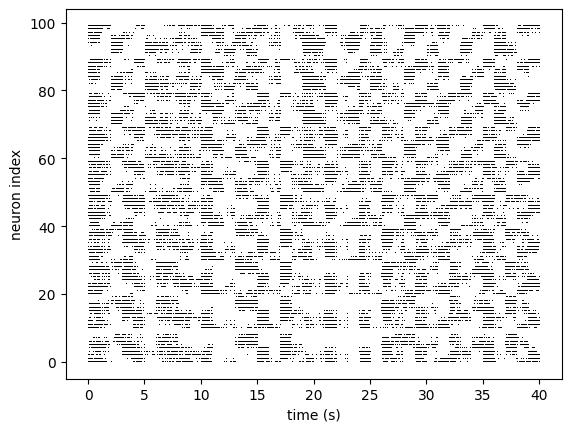

In [2]:
start_scope()
net = train(40, False) 
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
create_gif_from_frames(frames_inp, filename='inp_train_diag_no_alc_rad3.gif')
create_gif_from_frames(frames_rec,filename='rec_train_diag_no_alc_rad3.gif')
#create_gif_from_frames(frames_inp, filename='Main_Layer_fr_train_diag_alcohol.gif')
make_firing_rate_gif(net['sp_exc'], gif_filename="train_rates_no_alc_no_mask_rad3.gif", step=100*ms, window = 1*second)


In [10]:
make_firing_rate_gif(net['sp_exc'], gif_filename="train_rates_no_alc_no_mask.gif", step=100*ms, window = 1*second)


WARNING    /tmp/ipykernel_1480/2534006636.py:707: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  writer.append_data(imageio.imread(temp_file))
 [py.warnings]
  writer.append_data(imageio.imread(temp_file))



GIF saved as train_rates_no_alc_no_mask.gif


# Test no mask no alcohol

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    'post' is an internal variable of group 'E_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_E', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'E_I', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_I', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'I_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.r

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
[1000 ms]  rates (mean): 11.7 Hz  
[1100 ms]  rates (mean): 11.2 Hz  
[1200 ms]  rates (mean): 10.9 Hz  
[1300 ms]  rates (mean): 11.0 Hz  
[1400 ms]  rates (mean): 10.9 Hz  
[1500 ms]  rates (mean): 10.0 Hz  
[1600 ms]  rates (mean): 9.5 Hz  
[1700 ms]  rates (mean): 8.5 Hz  
[1800 ms]  rates (mean): 7.9 Hz  
[1900 ms]  rates (mean): 7.4 Hz  
[2000 ms]  rates (mean): 6.7 Hz  
[2100 ms]  rates (mean): 6.5 Hz  
[2200 ms]  rates (mean): 6.5 Hz  
[2300 ms]  rates (mean): 5.9 Hz  
[2400 ms]  rates (mean): 5.3 Hz  
[2500 ms]  rates (mean): 5.5 Hz  
[2600 ms]  rates (mean): 5.5 Hz  
[2700 ms]  rates (mean): 5.7 Hz  
[2800 ms]  rates (mean): 5.9 Hz  
[2900 ms]  rates (mean): 5.9 Hz  
[3000 ms]  rates (mean): 5.7 Hz  
[3100 ms]  rates (mean): 5.5 Hz  
[3200 ms]  rates (mean): 5.4 Hz  
[3300 ms]  rates (mean): 5.0 Hz  
[3400 ms]  rates (mean): 5.0 Hz  
[3500 ms]

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



[39900 ms]  rates (mean): 5.4 Hz  
Tested image 2/2


WARNING    /tmp/ipykernel_32421/2169332014.py:667: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(temp_path)
 [py.warnings]
  image = imageio.imread(temp_path)

WARNING    /tmp/ipykernel_32421/2169332014.py:707: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  writer.append_data(imageio.imread(temp_file))
 [py.warnings]
  writer.append_data(imageio.imread(temp_file))



✅ GIF saved as: rec_test_diag_no_alc_no_mask_2img_20s.gif
GIF saved as test_rates_no_alc_no_mask_2img_20s.gif


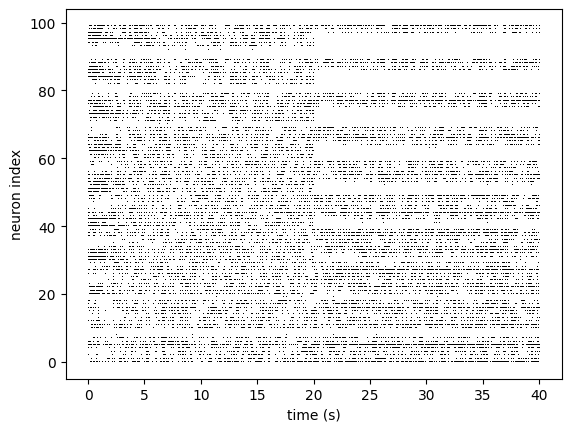

In [7]:
start_scope()
net = test(2,False,show_time=20*second)
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
# create_gif_from_frames(frames_inp,filename='inp_test_diag_no_alc.gif')
create_gif_from_frames(frames_rec,filename='rec_test_diag_no_alc_no_mask_2img_20s.gif')
make_firing_rate_gif(net['sp_exc'], gif_filename="test_rates_no_alc_no_mask_2img_20s.gif", step=100*ms, window = 1*second)


# Test no alcohol but mask

INFO:root:creating /tmp/brian_flag_test_sr_23ii5/tmp
INFO:root:creating /tmp/brian_flag_test_sr_23ii5/tmp/brian_flag_test_sr_23ii5
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_sr_23ii5/flag_test.cpp -o /tmp/brian_flag_test_sr_23ii5/tmp/brian_flag_test_sr_23ii5/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_kf6y5wtg/tmp
INFO:root:creating /tmp/brian_flag_test_kf6y5wtg/tmp/brian_flag_test_kf6y5wtg
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_kf6y5wtg/flag_test.cpp -o /tmp/brian_flag_test_kf6y5wtg/tmp/brian_flag_test_kf6y5wtg/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_4zwvrtzb/tmp
INFO:root:creating /tmp/brian_flag_test_4zwvrtzb/tmp/brian_flag_test_4zwvrtzb
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_4zwvrtzb/flag_test.cpp -o /tmp/brian_flag_test_4z

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    'post' is an internal variable of group 'E_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_E', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'E_I', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_I', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'I_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.r

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
[1000 ms]  rates (mean): 14.1 Hz  
[1100 ms]  rates (mean): 14.1 Hz  
[1200 ms]  rates (mean): 13.8 Hz  
[1300 ms]  rates (mean): 13.4 Hz  
[1400 ms]  rates (mean): 13.5 Hz  
[1500 ms]  rates (mean): 13.2 Hz  
[1600 ms]  rates (mean): 12.4 Hz  
[1700 ms]  rates (mean): 11.9 Hz  
[1800 ms]  rates (mean): 11.2 Hz  
[1900 ms]  rates (mean): 10.7 Hz  
[2000 ms]  rates (mean): 10.5 Hz  
[2100 ms]  rates (mean): 10.1 Hz  
[2200 ms]  rates (mean): 9.5 Hz  
[2300 ms]  rates (mean): 9.4 Hz  
[2400 ms]  rates (mean): 8.8 Hz  
[2500 ms]  rates (mean): 8.7 Hz  
[2600 ms]  rates (mean): 9.2 Hz  
[2700 ms]  rates (mean): 9.4 Hz  
[2800 ms]  rates (mean): 9.6 Hz  
[2900 ms]  rates (mean): 9.6 Hz  
[3000 ms]  rates (mean): 9.8 Hz  
[3100 ms]  rates (mean): 9.9 Hz  
[3200 ms]  rates (mean): 10.5 Hz  
[3300 ms]  rates (mean): 10.6 Hz  
[3400 ms]  rates (mean): 10.5 Hz  


WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



[44900 ms]  rates (mean): 10.0 Hz  
Tested image 3/3


WARNING    /tmp/ipykernel_20741/3303295200.py:667: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(temp_path)
 [py.warnings]
  image = imageio.imread(temp_path)

WARNING    /tmp/ipykernel_20741/3303295200.py:707: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  writer.append_data(imageio.imread(temp_file))
 [py.warnings]
  writer.append_data(imageio.imread(temp_file))



✅ GIF saved as: rec_test_diag_no_alc_mask_3img_15s_rad3.gif
✅ GIF saved as test_rates_no_alc_mask_3img_15s_rad3.gif


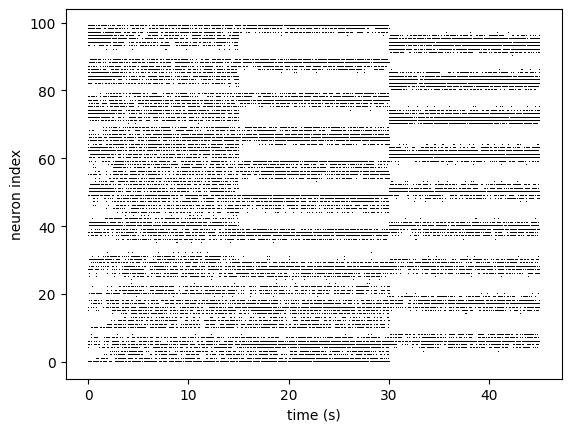

: 

In [ ]:
start_scope()
net = test(3,False,show_time=15*second)
exc_mon = net['sp_exc']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
# create_gif_from_frames(frames_inp,filename='inp_test_diag_no_alc.gif')
create_gif_from_frames(frames_rec,filename='rec_test_diag_no_alc_mask_3img_15s_rad3.gif')
make_firing_rate_gif(net['sp_exc'], gif_filename="test_rates_no_alc_mask_3img_15s_rad3.gif", step=100*ms, window = 1*second)